In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "Video_Games_Sales_as_at_22_Dec_2016.csv",
    encoding="utf-8-sig"
)
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


# Data Understanding

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (16719, 16)


In [4]:
df.columns

Index(['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score',
       'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       7590 non-null   float64
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(10), object(6)
memory usage: 2.0+ MB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
Name,2
Platform,0
Year_of_Release,269
Genre,2
Publisher,54
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0
Global_Sales,0


In [8]:
df[df['Year_of_Release'] >= 2017][
    ['Name', 'Platform', 'Year_of_Release', 'Global_Sales', 'Publisher']
].sort_values('Year_of_Release')

,Name,Platform,Year_of_Release,Global_Sales,Publisher
14086,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017.0,0.04,Sega
16222,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017.0,0.01,Sega
16385,Brothers Conflict: Precious Baby,PSV,2017.0,0.01,Idea Factory
5936,Imagine: Makeup Artist,DS,2020.0,0.29,Ubisoft


In [9]:
df_clean = df.copy()

In [10]:
df_clean['User_Score'].value_counts().head(20)

,count
User_Score,
7.8,324
8.0,290
8.2,282
8.3,254
8.5,253
7.5,251
7.9,249
8.1,244
7.7,240


In [11]:
df_clean['User_Score'] = df_clean['User_Score'].replace('tbd', np.nan)
df_clean['User_Score'] = pd.to_numeric(
    df_clean['User_Score'],
    errors='coerce'
)

In [12]:
df_clean['User_Score'].dtype

dtype('float64')

In [13]:
df_clean['User_Score'].isna().sum()

np.int64(9129)

In [14]:
numeric_cols = [
    'Year_of_Release',
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales',
    'Critic_Score',
    'Critic_Count',
    'User_Score',
    'User_Count'
]

df_clean[numeric_cols].describe()

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count
count,16450.000000,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000,7590.000000
mean,2006.487356,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,7.125046,162.229908
std,5.878995,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,1.500006,561.282326
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,0.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,6.400000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,7.500000,24.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,8.200000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,82.530000,98.000000,113.000000,9.700000,10665.000000


In [15]:
missing = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing %': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
})

missing = missing[missing['Missing Values'] > 0] \
    .sort_values('Missing %', ascending=False)

missing

,Missing Values,Missing %
User_Score,9129,54.60
User_Count,9129,54.60
Critic_Count,8582,51.33
Critic_Score,8582,51.33
Rating,6769,40.49
Developer,6623,39.61
Year_of_Release,269,1.61
Publisher,54,0.32
Name,2,0.01
Genre,2,0.01


# Data Cleaning

In [16]:
df_clean['Rating'] = df_clean['Rating'].fillna('Not Rated')
df_clean['Developer'] = df_clean['Developer'].fillna('Unknown')
df_clean['Publisher'] = df_clean['Publisher'].fillna('Unknown')

publisher_sales = (
    df_clean[df_clean['Publisher'] != 'Unknown']
    .groupby('Publisher')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)

df_clean = df_clean.dropna(subset=['Genre'])
df_clean = df_clean.dropna(subset=['Name'])

In [17]:
print("Shape after missing-value handling:", df_clean.shape)

Shape after missing-value handling: (16717, 16)


In [18]:
df_clean['Year_of_Release'].describe()

,Year_of_Release
count,16448.000000
mean,2006.488996
std,5.877470
min,1980.000000
25%,2003.000000
50%,2007.000000
75%,2010.000000
max,2020.000000


In [19]:
df_clean['Year_of_Release'].value_counts().sort_index().tail(20)

,count
Year_of_Release,
1999.0,338
2000.0,350
2001.0,482
2002.0,829
2003.0,775
2004.0,762
2005.0,939
2006.0,1006
2007.0,1197


In [20]:
df_clean[df_clean['Year_of_Release'] > 2016][
    ['Name', 'Platform', 'Year_of_Release', 'Global_Sales']
].sort_values('Year_of_Release')

,Name,Platform,Year_of_Release,Global_Sales
14086,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017.0,0.04
16222,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017.0,0.01
16385,Brothers Conflict: Precious Baby,PSV,2017.0,0.01
5936,Imagine: Makeup Artist,DS,2020.0,0.29


In [21]:
df_clean = df_clean[
    (df_clean['Year_of_Release'].isna()) |
    (df_clean['Year_of_Release'] <= 2016)
]

## Duplicate Investigation

In [22]:
df_clean.duplicated().sum()

np.int64(0)

In [23]:
duplicate_keys = df_clean.duplicated(
    subset=['Name', 'Platform', 'Year_of_Release'],
    keep=False
)

df_clean[duplicate_keys].sort_values(
    ['Name', 'Platform', 'Year_of_Release']
)

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
604,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,2.11,0.22,0.0,0.23,2.56,83.0,22.0,5.5,101.0,EA Tiburon,E
16233,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.0,0.00,0.01,83.0,22.0,5.5,101.0,EA Tiburon,E


In [24]:
df_clean[
    (df_clean['Name'] == 'Madden NFL 13') &
    (df_clean['Platform'] == 'PS3') &
    (df_clean['Year_of_Release'] == 2012)
]

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
604,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,2.11,0.22,0.0,0.23,2.56,83.0,22.0,5.5,101.0,EA Tiburon,E
16233,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.0,0.00,0.01,83.0,22.0,5.5,101.0,EA Tiburon,E


### Text Columns

In [25]:
text_cols = [
    'Name',
    'Platform',
    'Genre',
    'Publisher',
    'Developer',
    'Rating'
]

In [26]:
for col in text_cols:
    df_clean[col] = df_clean[col].astype('string').str.strip()

In [27]:
for col in ['Platform', 'Genre', 'Rating']:
    print(f"\n{col}:")
    print(df_clean[col].unique())


Platform:
<StringArray>
[ 'Wii',  'NES',   'GB',   'DS', 'X360',  'PS3',  'PS2', 'SNES',  'GBA',
  'PS4',  '3DS',  'N64',   'PS',   'XB',   'PC', '2600',  'PSP', 'XOne',
 'WiiU',   'GC',  'GEN',   'DC',  'PSV',  'SAT',  'SCD',   'WS',   'NG',
 'TG16',  '3DO',   'GG', 'PCFX']
Length: 31, dtype: string

Genre:
<StringArray>
[      'Sports',     'Platform',       'Racing', 'Role-Playing',
       'Puzzle',         'Misc',      'Shooter',   'Simulation',
       'Action',     'Fighting',    'Adventure',     'Strategy']
Length: 12, dtype: string

Rating:
<StringArray>
['E', 'Not Rated', 'M', 'T', 'E10+', 'K-A', 'AO', 'EC', 'RP']
Length: 9, dtype: string


### Data Type Year

In [28]:
df_clean['Year_of_Release'] = df_clean['Year_of_Release'].astype('Int64')

In [29]:
sales_cols = [
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales'
]

(df_clean[sales_cols] < 0).sum()

,0
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0
Global_Sales,0


In [30]:
regional_sales = (
    df_clean['NA_Sales']
    + df_clean['EU_Sales']
    + df_clean['JP_Sales']
    + df_clean['Other_Sales']
)

sales_difference = (
    df_clean['Global_Sales'] - regional_sales
).abs()

sales_difference.describe()

,0
count,16713.000000
mean,0.002714
std,0.004458
min,0.000000
25%,0.000000
50%,0.000000
75%,0.010000
max,0.020000


In [31]:
print("Final Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nNegative Sales:")
print((df_clean[sales_cols] < 0).sum())

Final Shape: (16713, 16)

Missing Values:
Name                  0
Platform              0
Year_of_Release     269
Genre                 0
Publisher             0
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Critic_Score       8576
Critic_Count       8576
User_Score         9123
User_Count         9123
Developer             0
Rating                0
dtype: int64

Duplicate Rows:
0

Data Types:
Name               string[python]
Platform           string[python]
Year_of_Release             Int64
Genre              string[python]
Publisher          string[python]
NA_Sales                  float64
EU_Sales                  float64
JP_Sales                  float64
Other_Sales               float64
Global_Sales              float64
Critic_Score              float64
Critic_Count              float64
User_Score                float64
User_Count                float64
Developer          string[python]
Rating             

# (EDA) — Video Game

### Genre Analysis

In [32]:
genre_count = (
    df_clean['Genre']
    .value_counts()
    .sort_values(ascending=False)
)

genre_sales = (
    df_clean
    .groupby('Genre')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)

genre_avg_sales = (
    df_clean
    .groupby('Genre')['Global_Sales']
    .mean()
    .sort_values(ascending=False)
)

genre_analysis = pd.DataFrame({
    'Game_Count': genre_count,
    'Global_Sales': genre_sales,
    'Average_Sales_Per_Game': genre_avg_sales
}).sort_values(
    'Global_Sales',
    ascending=False
)

genre_analysis

,Game_Count,Global_Sales,Average_Sales_Per_Game
Genre,,,
Action,3369,1745.26,0.518035
Sports,2348,1332.00,0.567291
Shooter,1323,1052.94,0.795873
Role-Playing,1498,934.35,0.623732
Platform,888,828.08,0.932523
Misc,1750,803.18,0.458960
Racing,1249,728.90,0.583587
Fighting,849,447.48,0.527067
Simulation,873,390.13,0.446884


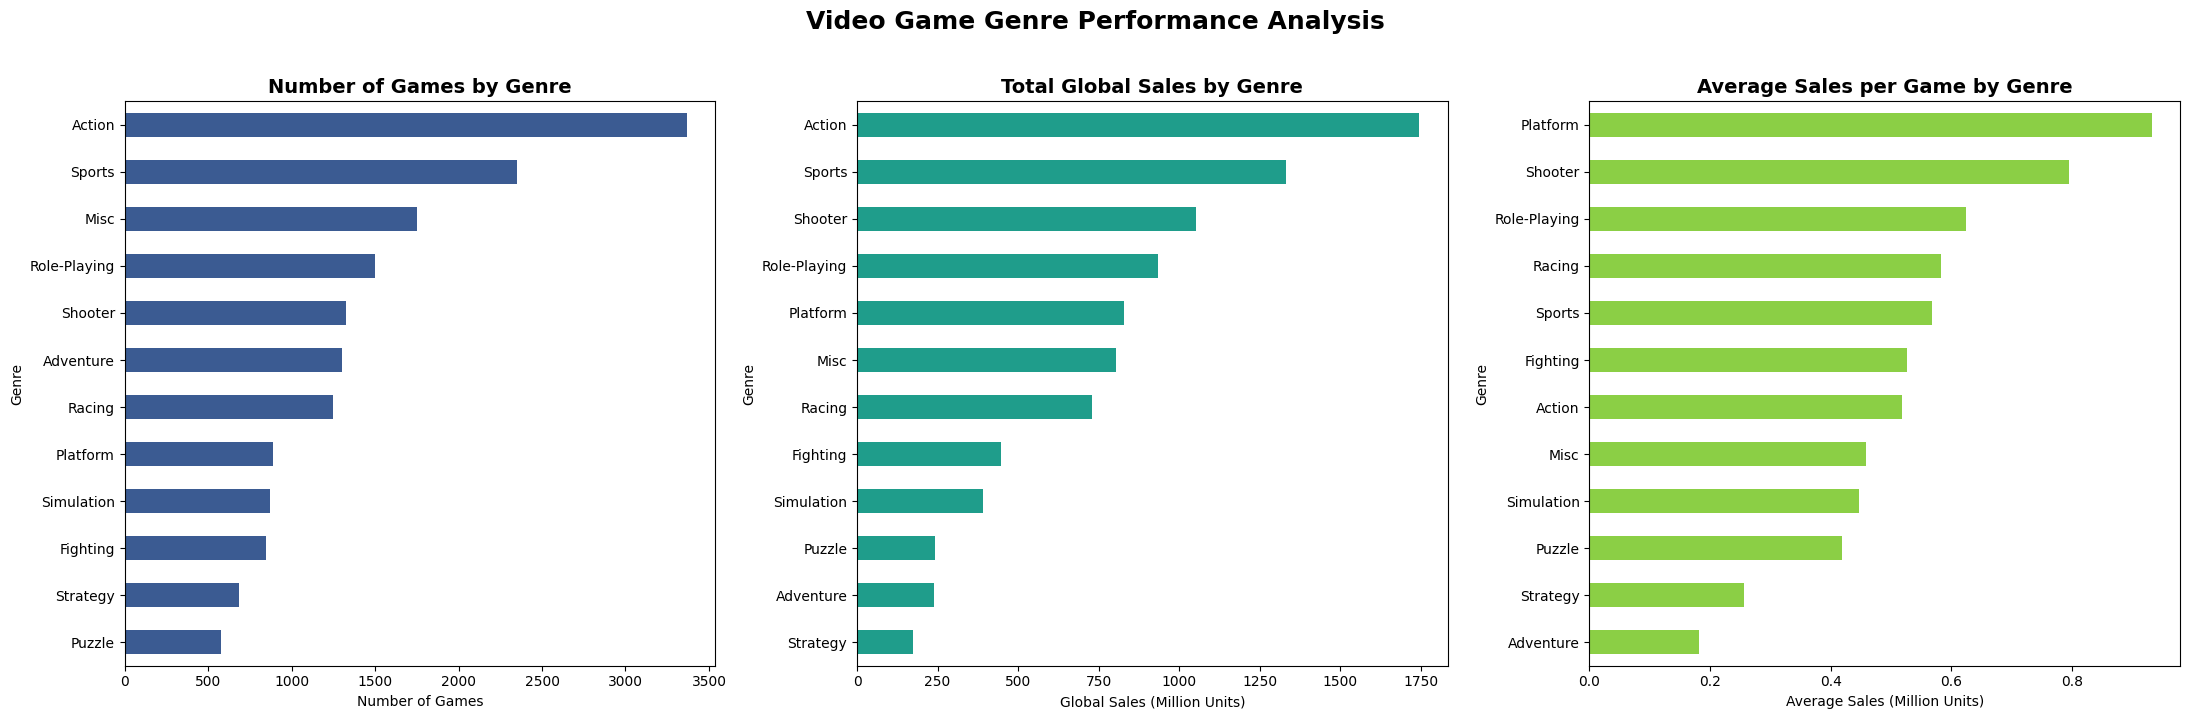

In [33]:
colors = {
    'count': '#3B5B92',
    'sales': '#1F9D8B',
    'average': '#8BCF45'
}

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# 1️⃣ Number of Games
genre_count.sort_values().plot(
    kind='barh',
    ax=axes[0],
    color=colors['count']
)

axes[0].set_title(
    'Number of Games by Genre',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('Number of Games')
axes[0].set_ylabel('Genre')


# 2️⃣ Total Global Sales
genre_sales.sort_values().plot(
    kind='barh',
    ax=axes[1],
    color=colors['sales']
)

axes[1].set_title(
    'Total Global Sales by Genre',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('Global Sales (Million Units)')
axes[1].set_ylabel('Genre')


# 3️⃣ Average Sales per Game
genre_avg_sales.sort_values().plot(
    kind='barh',
    ax=axes[2],
    color=colors['average']
)

axes[2].set_title(
    'Average Sales per Game by Genre',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_xlabel('Average Sales (Million Units)')
axes[2].set_ylabel('Genre')


# Main title
fig.suptitle(
    'Video Game Genre Performance Analysis',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

# Platform Analysis

In [34]:
platform_sales = (
    df_clean
    .groupby('Platform')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)
top12_platform_sales = platform_sales.head(12).sort_values(ascending=True)

In [35]:
manufacturer_map = {
    'PS': 'Sony',
    'PS2': 'Sony',
    'PS3': 'Sony',
    'PS4': 'Sony',
    'PSP': 'Sony',
    'PSV': 'Sony',

    'NES': 'Nintendo',
    'SNES': 'Nintendo',
    'N64': 'Nintendo',
    'GB': 'Nintendo',
    'GBA': 'Nintendo',
    'GC': 'Nintendo',
    'DS': 'Nintendo',
    '3DS': 'Nintendo',
    'Wii': 'Nintendo',
    'WiiU': 'Nintendo',

    'XB': 'Microsoft',
    'X360': 'Microsoft',
    'XOne': 'Microsoft',

    'DC': 'Sega',
    'GEN': 'Sega',
    'GG': 'Sega',
    'SAT': 'Sega',
    'SCD': 'Sega',

    '2600': 'Atari',

    'TG16': 'NEC',
    'PCFX': 'NEC',

    'NG': 'SNK',

    'WS': 'Bandai',

    '3DO': 'Panasonic',

    'PC': 'PC'
}

In [36]:
df_clean['Manufacturer'] = df_clean['Platform'].map(manufacturer_map)

In [37]:
df_clean[df_clean['Manufacturer'].isna()]['Platform'].unique()

<StringArray>
[]
Length: 0, dtype: string

In [38]:
manufacturer_sales = (
    df_clean
    .groupby('Manufacturer')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)
top_manufacturers = manufacturer_sales.head(6)
other_sales = manufacturer_sales.iloc[6:].sum()

manufacturer_share = (
    manufacturer_sales /
    manufacturer_sales.sum() * 100
)

manufacturer_donut = pd.concat([
    top_manufacturers,
    pd.Series({'Other': other_sales})
])


manufacturer_share

,Global_Sales
Manufacturer,
Sony,40.239169
Nintendo,39.242929
Microsoft,15.579763
PC,2.918970
Atari,1.088642
Sega,0.895203
SNK,0.016148
Bandai,0.015924
NEC,0.002131


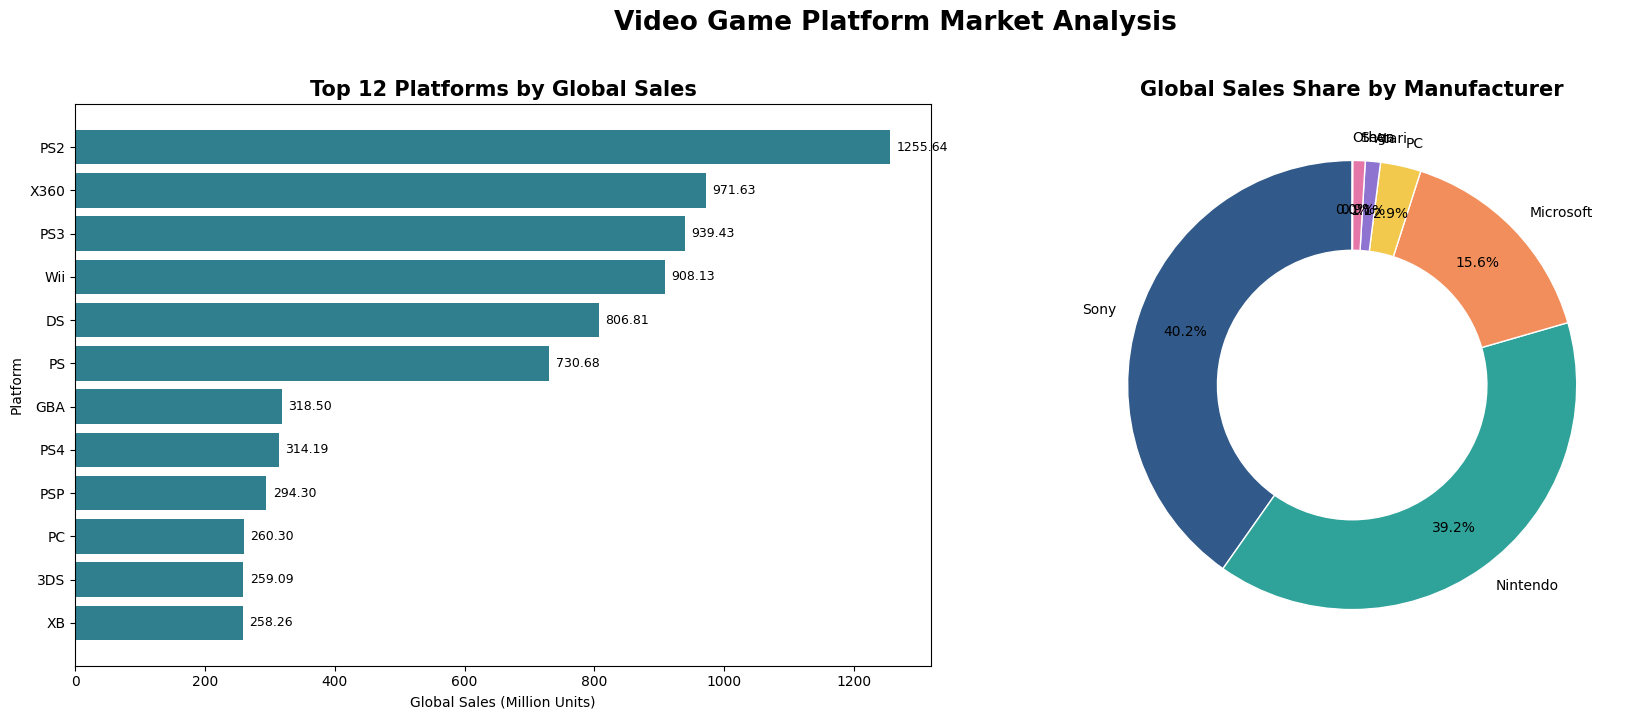

In [39]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7)
)

bars = axes[0].barh(
    top12_platform_sales.index,
    top12_platform_sales.values,
    color='#2F7F8F'
)

axes[0].set_title(
    'Top 12 Platforms by Global Sales',
    fontsize=15,
    fontweight='bold'
)

axes[0].set_xlabel(
    'Global Sales (Million Units)'
)

axes[0].set_ylabel('Platform')

for bar, value in zip(
    bars,
    top12_platform_sales.values
):
    axes[0].text(
        bar.get_width() + 10,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}',
        va='center',
        fontsize=9
    )

axes[1].pie(
    manufacturer_donut.values,
    labels=manufacturer_donut.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        'width': 0.40,
        'edgecolor': 'white'
    },
    colors=[
        '#315A8A',
        '#2FA39A',
        '#F28E5B',
        '#F2C94C',
        '#8E73D1',
        '#E477A8',
        '#B0B0B0'
    ]
)

axes[1].set_title(
    'Global Sales Share by Manufacturer',
    fontsize=15,
    fontweight='bold'
)

fig.suptitle(
    'Video Game Platform Market Analysis',
    fontsize=19,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

# Publisher Analysis

In [40]:
publisher_sales = (
    df_clean
    .groupby('Publisher')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)
top15_publishers = publisher_sales.head(15)
top10_names = publisher_sales.head(10).index

In [41]:
publisher_cumulative = (
    top15_publishers.cumsum()
    / publisher_sales.sum()
    * 100
)

publisher_cumulative

,Global_Sales
Publisher,
Nintendo,20.059478
Electronic Arts,32.584920
Activision,40.784051
Sony Computer Entertainment,47.585038
Ubisoft,52.870358
Take-Two Interactive,57.398742
THQ,61.193963
Konami Digital Entertainment,64.360647
Sega,67.391755


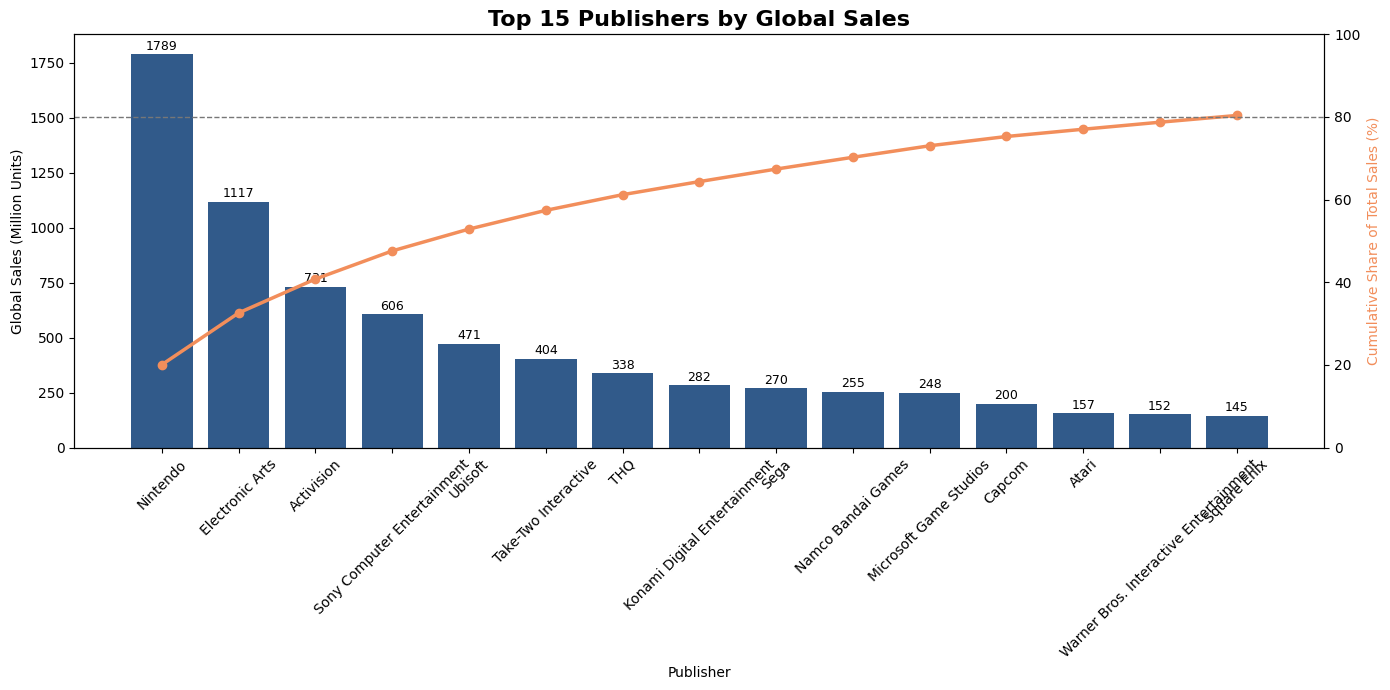

In [42]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 7))

bars = ax1.bar(
    top15_publishers.index,
    top15_publishers.values,
    color='#315A8A'
)

ax1.set_title(
    'Top 15 Publishers by Global Sales',
    fontsize=16,
    fontweight='bold'
)

ax1.set_ylabel('Global Sales (Million Units)')
ax1.set_xlabel('Publisher')

ax1.tick_params(axis='x', rotation=45)

for bar, value in zip(
    bars,
    top15_publishers.values
):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f'{value:.0f}',
        ha='center',
        fontsize=9
    )

ax2 = ax1.twinx()

ax2.plot(
    top15_publishers.index,
    publisher_cumulative.values,
    color='#F28E5B',
    marker='o',
    linewidth=2.5
)

ax2.set_ylabel(
    'Cumulative Share of Total Sales (%)',
    color='#F28E5B'
)

ax2.set_ylim(0, 100)


ax2.axhline(
    80,
    color='#777777',
    linestyle='--',
    linewidth=1
)

plt.tight_layout()
plt.show()

In [43]:
publisher_stats = (
    df_clean
    .groupby('Publisher')
    .agg(
        Game_Count=('Name', 'count'),
        Global_Sales=('Global_Sales', 'sum'),
        Average_Sales_Per_Game=('Global_Sales', 'mean')
    )
)
publisher_avg_filtered = publisher_stats[
    publisher_stats['Game_Count'] >= 30
]
top10_publishers_avg = (
    publisher_avg_filtered
    .sort_values(
        'Average_Sales_Per_Game',
        ascending=False
    )
    .head(10)
)

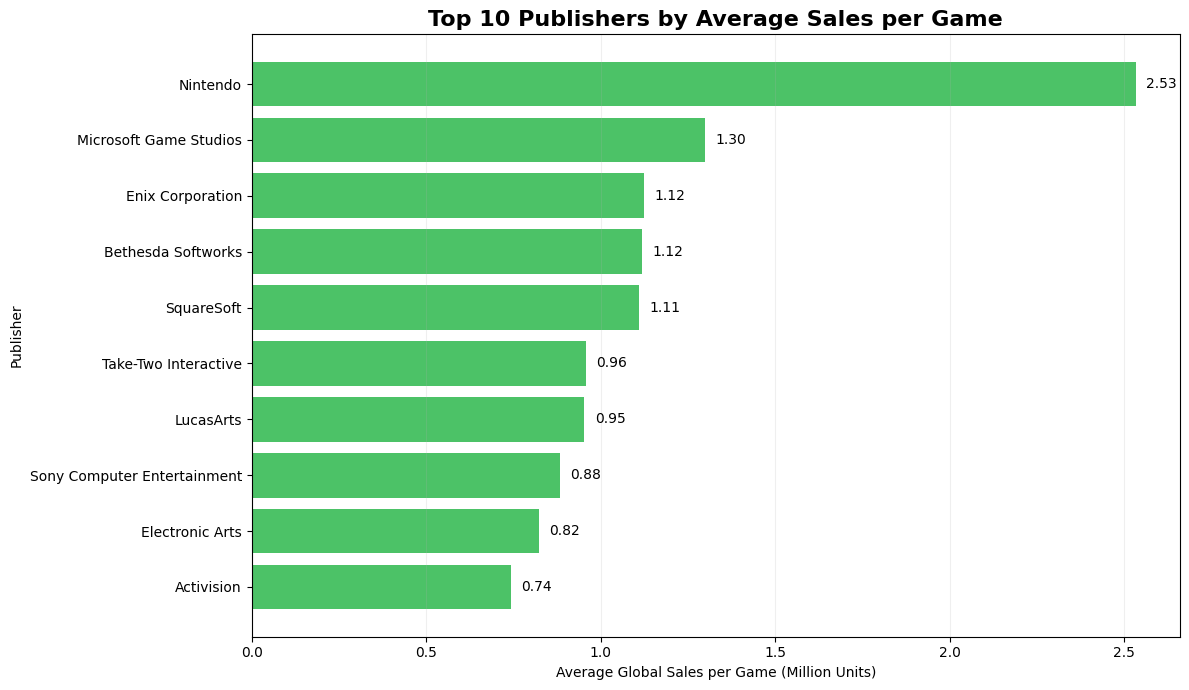

In [44]:
top10_avg = (
    top10_publishers_avg['Average_Sales_Per_Game']
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top10_avg.index,
    top10_avg.values,
    color='#4CC267'
)

plt.title(
    'Top 10 Publishers by Average Sales per Game',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Average Global Sales per Game (Million Units)')
plt.ylabel('Publisher')

for bar, value in zip(bars, top10_avg.values):
    plt.text(
        bar.get_width() + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}',
        va='center',
        fontsize=10
    )

plt.grid(
    axis='x',
    alpha=0.2
)

plt.tight_layout()
plt.show()

# Top-Selling Games

In [45]:
top10_games = (
    df_clean[
        ['Name', 'Platform', 'Genre', 'Publisher', 'Global_Sales']
    ]
    .sort_values(
        'Global_Sales',
        ascending=False
    )
    .head(10)
)


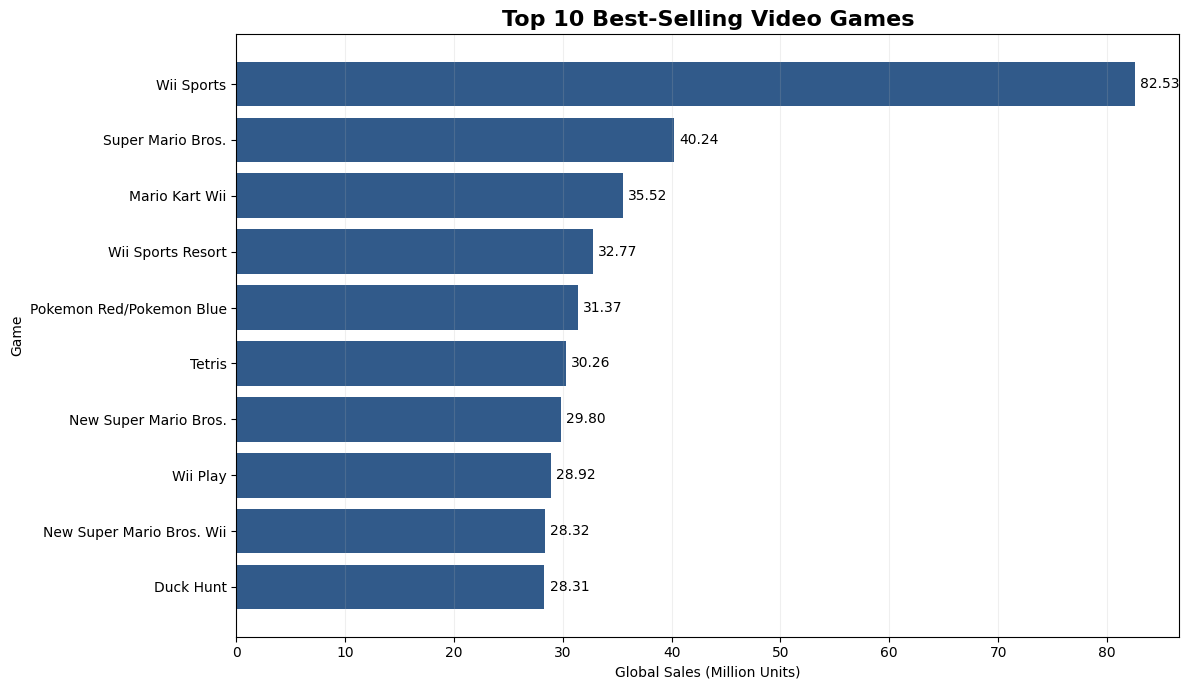

In [46]:
top10_games_plot = (
    top10_games
    .sort_values('Global_Sales', ascending=True)
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top10_games_plot['Name'],
    top10_games_plot['Global_Sales'],
    color='#315A8A'
)

plt.title(
    'Top 10 Best-Selling Video Games',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Global Sales (Million Units)')
plt.ylabel('Game')

for bar, value in zip(
    bars,
    top10_games_plot['Global_Sales']
):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.2f}',
        va='center',
        fontsize=10
    )

plt.grid(
    axis='x',
    alpha=0.2
)

plt.tight_layout()
plt.show()

In [47]:
top10_sales_share = (
    top10_games['Global_Sales'].sum()
    / df_clean['Global_Sales'].sum()
    * 100
)

print(
    f"Top 10 games account for "
    f"{top10_sales_share:.2f}% of total global sales."
)

Top 10 games account for 4.13% of total global sales.


# Sales Trend Over Years

In [48]:
yearly_analysis = (
    df_clean
    .dropna(subset=['Year_of_Release'])
    .groupby('Year_of_Release')
    .agg(
        Global_Sales=('Global_Sales', 'sum'),
        Game_Releases=('Name', 'count')
    )
    .sort_index()
)
peak_year = yearly_analysis['Global_Sales'].idxmax()
peak_sales = yearly_analysis['Global_Sales'].max()

print("Peak Sales Year:", peak_year)
print(f"Peak Global Sales: {peak_sales:.2f} Million Units")

Peak Sales Year: 2008
Peak Global Sales: 671.79 Million Units


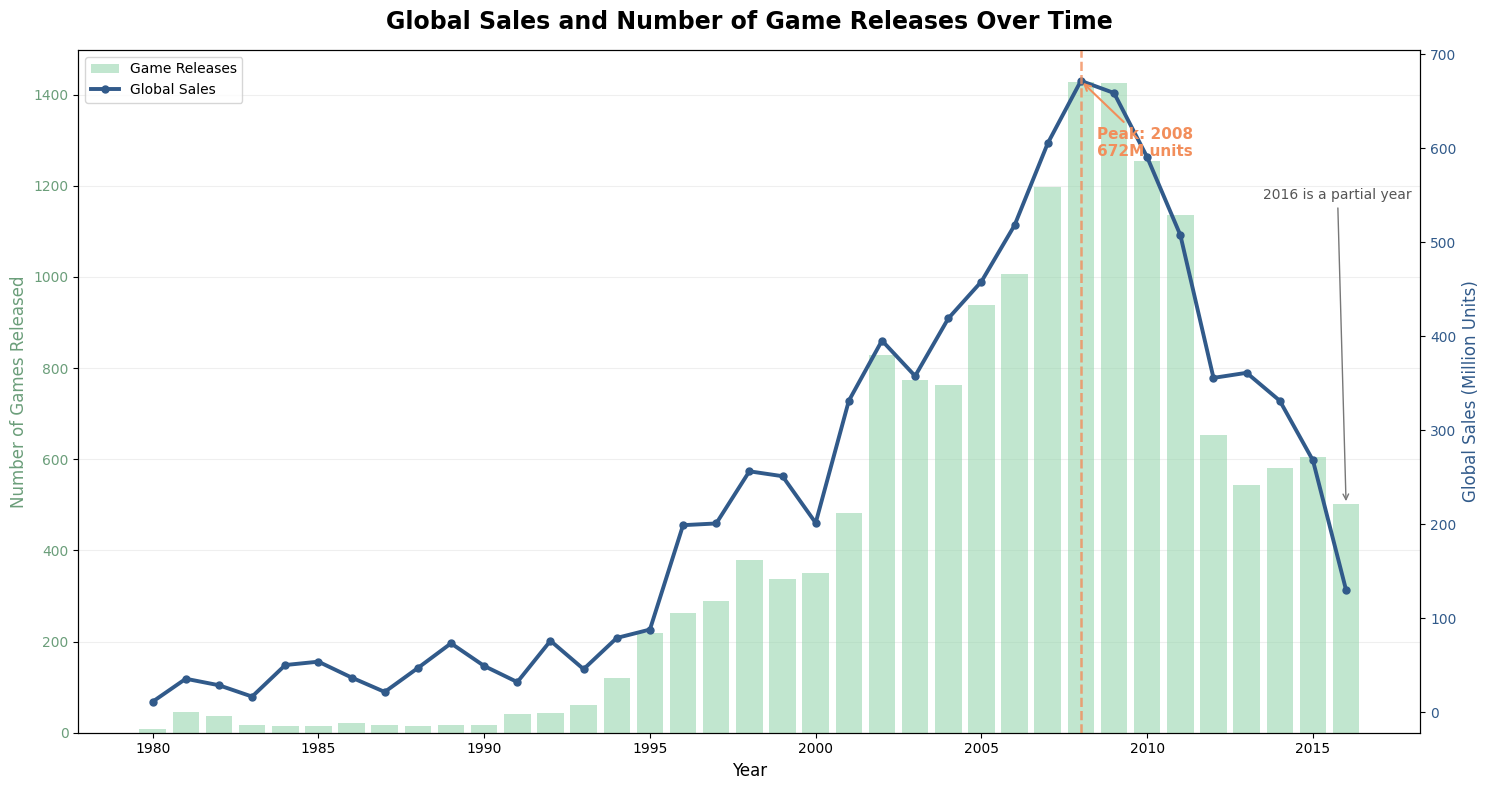

In [49]:

fig, ax1 = plt.subplots(figsize=(15, 8))

bars = ax1.bar(
    yearly_analysis.index,
    yearly_analysis['Game_Releases'],
    color='#8FD3A8',
    alpha=0.55,
    width=0.8,
    label='Game Releases'
)

ax1.set_xlabel(
    'Year',
    fontsize=12
)

ax1.set_ylabel(
    'Number of Games Released',
    fontsize=12,
    color='#6B9E7A'
)

ax1.tick_params(
    axis='y',
    labelcolor='#6B9E7A'
)


ax2 = ax1.twinx()

line = ax2.plot(
    yearly_analysis.index,
    yearly_analysis['Global_Sales'],
    color='#315A8A',
    marker='o',
    linewidth=2.8,
    markersize=5,
    label='Global Sales'
)

ax2.set_ylabel(
    'Global Sales (Million Units)',
    fontsize=12,
    color='#315A8A'
)

ax2.tick_params(
    axis='y',
    labelcolor='#315A8A'
)


ax2.axvline(
    peak_year,
    color='#F28E5B',
    linestyle='--',
    linewidth=1.8,
    alpha=0.8
)

ax2.annotate(
    f'Peak: {peak_year}\n{peak_sales:.0f}M units',
    xy=(peak_year, peak_sales),
    xytext=(peak_year + 0.5, peak_sales - 80),
    fontsize=11,
    fontweight='bold',
    color='#F28E5B',
    arrowprops=dict(
        arrowstyle='->',
        color='#F28E5B',
        linewidth=1.5
    )
)


if 2016 in yearly_analysis.index:

    ax1.annotate(
        '2016 is a partial year',
        xy=(2016, yearly_analysis.loc[2016, 'Game_Releases']),
        xytext=(2013.5, yearly_analysis['Game_Releases'].max() * 0.82),
        fontsize=10,
        color='#555555',
        arrowprops=dict(
            arrowstyle='->',
            color='#777777'
        )
    )


plt.title(
    'Global Sales and Number of Game Releases Over Time',
    fontsize=17,
    fontweight='bold',
    pad=15
)


ax1.grid(
    axis='y',
    alpha=0.20
)

ax1.set_axisbelow(True)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc='upper left',
    frameon=True
)


plt.tight_layout()
plt.show()

In [50]:
print("Peak Sales Year:", peak_year)
print(f"Peak Sales: {peak_sales:.2f} Million Units")

print(
    "\nYear with highest number of releases:",
    yearly_analysis['Game_Releases'].idxmax()
)

print(
    "Maximum releases:",
    yearly_analysis['Game_Releases'].max()
)

Peak Sales Year: 2008
Peak Sales: 671.79 Million Units

Year with highest number of releases: 2008
Maximum releases: 1427


In [51]:
full_years = yearly_analysis[
    yearly_analysis.index < 2016
]

print(
    "Last complete year:",
    full_years.index.max()
)

print(
    "Sales in last complete year:",
    full_years.loc[
        full_years.index.max(),
        'Global_Sales'
    ]
)

Last complete year: 2015
Sales in last complete year: 268.05


In [52]:
top6_genres = (
    df_clean
    .groupby('Genre')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(6)
)

print("Top 6 Genres:")
print(top6_genres)

Top 6 Genres:
Genre
Action          1745.26
Sports          1332.00
Shooter         1052.94
Role-Playing     934.35
Platform         828.08
Misc             803.18
Name: Global_Sales, dtype: float64


In [53]:
genre_yearly_sales = (
    df_clean[
        df_clean['Genre'].isin(top6_genres.index)
    ]
    .dropna(subset=['Year_of_Release'])
    .groupby(['Year_of_Release', 'Genre'])['Global_Sales']
    .sum()
    .unstack(fill_value=0)
)

### Sales Trend for Top 6 Genres

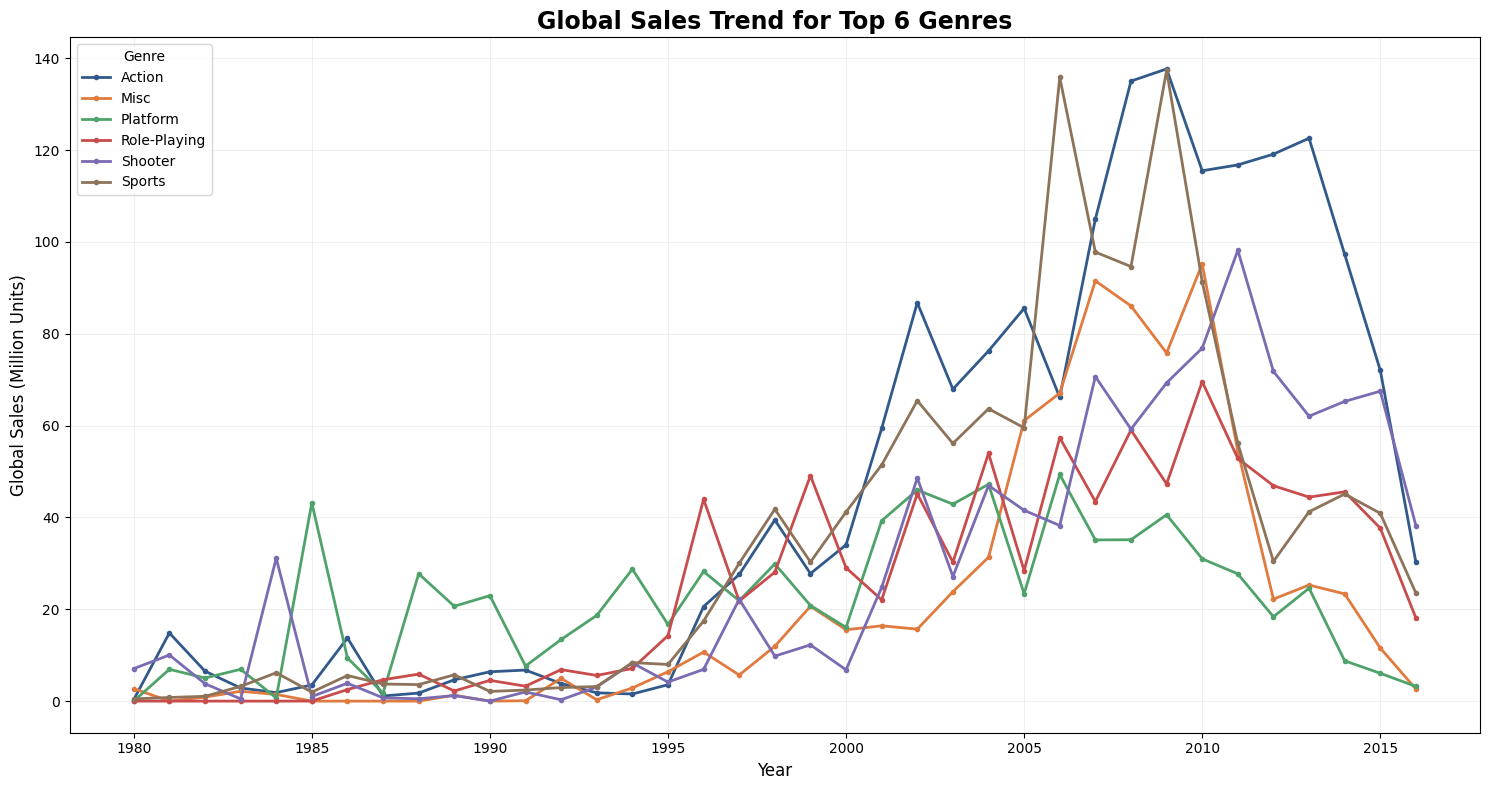

In [54]:
genre_colors = [
    '#315A8A',
    '#E07A3F',
    '#4FA36A',
    '#C94C4C',
    '#7B6BB3',
    '#8C735A'
]

plt.figure(figsize=(15, 8))

for genre, color in zip(
    genre_yearly_sales.columns,
    genre_colors
):

    plt.plot(
        genre_yearly_sales.index,
        genre_yearly_sales[genre],
        marker='o',
        markersize=3,
        linewidth=2,
        label=genre,
        color=color
    )

plt.title(
    'Global Sales Trend for Top 6 Genres',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel(
    'Year',
    fontsize=12
)

plt.ylabel(
    'Global Sales (Million Units)',
    fontsize=12
)

plt.legend(
    title='Genre',
    loc='upper left'
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()
plt.show()

### Sales by Manufacturer Over Time

In [55]:
manufacturer_yearly_sales = (
    df_clean
    .dropna(subset=['Year_of_Release', 'Manufacturer'])
    .groupby([
        'Year_of_Release',
        'Manufacturer'
    ])['Global_Sales']
    .sum()
    .unstack(fill_value=0)
)
top_manufacturers = (
    df_clean
    .groupby('Manufacturer')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(6)
)
manufacturer_yearly_top = (
    manufacturer_yearly_sales[
        top_manufacturers.index
    ]
)

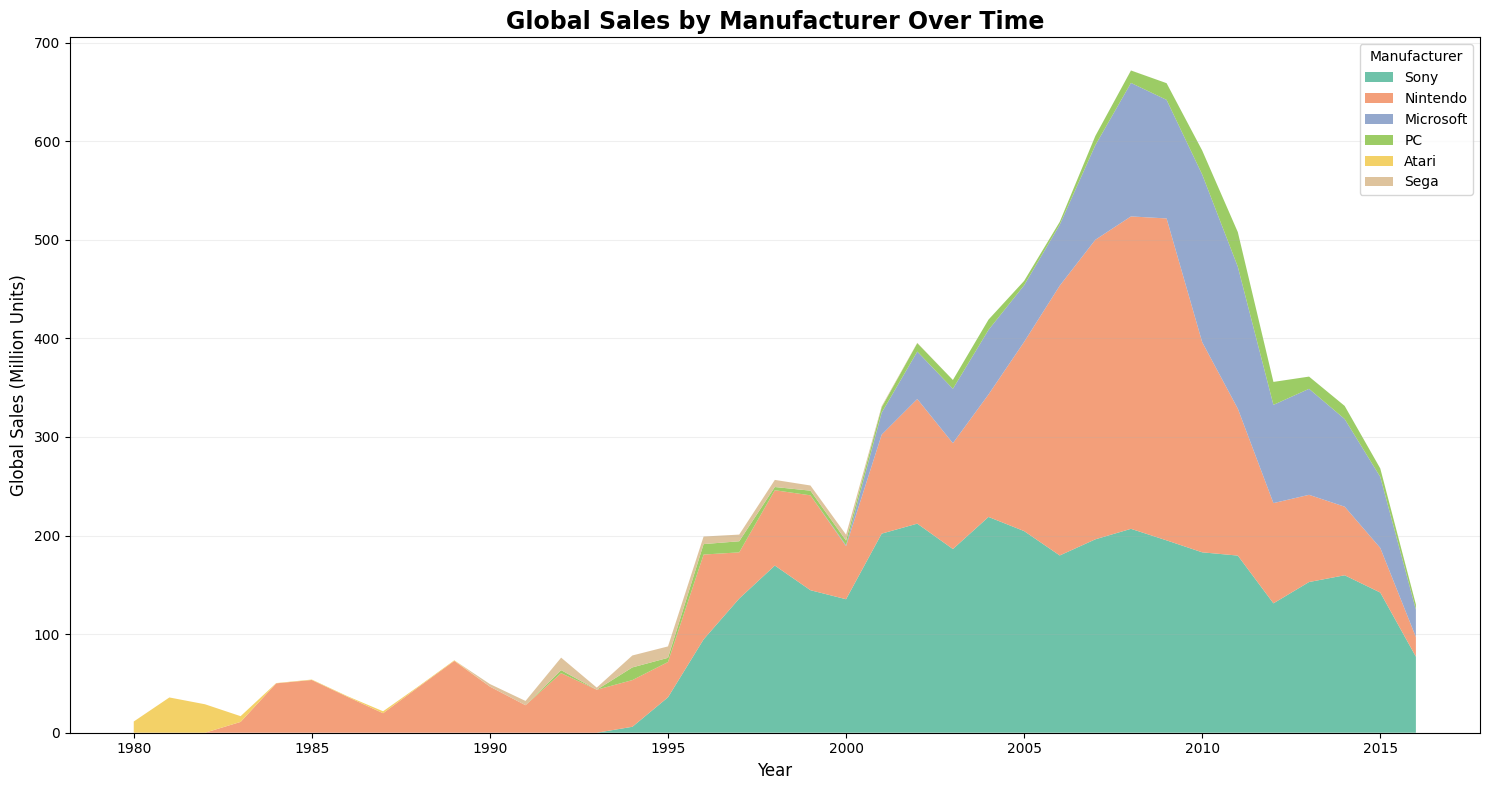

In [56]:
manufacturer_colors = [
    '#55B89A',
    '#F28E63',
    '#8299C5',
    '#8BC34A',
    '#F2C94C',
    '#D9B98C'
]

plt.figure(figsize=(15, 8))

plt.stackplot(
    manufacturer_yearly_top.index,
    [
        manufacturer_yearly_top[col]
        for col in manufacturer_yearly_top.columns
    ],
    labels=manufacturer_yearly_top.columns,
    colors=manufacturer_colors[:len(manufacturer_yearly_top.columns)],
    alpha=0.85
)

plt.title(
    'Global Sales by Manufacturer Over Time',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel(
    'Year',
    fontsize=12
)

plt.ylabel(
    'Global Sales (Million Units)',
    fontsize=12
)

plt.legend(
    title='Manufacturer',
    loc='upper right'
)

plt.grid(
    axis='y',
    alpha=0.2
)

plt.tight_layout()
plt.show()

# Regional Sales Analysis

In [57]:
regional_sales = df_clean[
    [
        'NA_Sales',
        'EU_Sales',
        'JP_Sales',
        'Other_Sales'
    ]
].sum()

regional_sales.index = [
    'North America',
    'Europe',
    'Japan',
    'Other'
]
regional_share = (
    regional_sales /
    regional_sales.sum()
    * 100
)


In [58]:
top6_genres = (
    df_clean
    .groupby('Genre')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index
)
region_genre_sales = (
    df_clean[
        df_clean['Genre'].isin(top6_genres)
    ]
    .groupby('Genre')[
        [
            'NA_Sales',
            'EU_Sales',
            'JP_Sales',
            'Other_Sales'
        ]
    ]
    .sum()
)
region_genre_share = (
    region_genre_sales
    .div(
        regional_sales.values,
        axis=1
    )
    * 100
)

###  Regional Sales Analysis — Combined Visualization

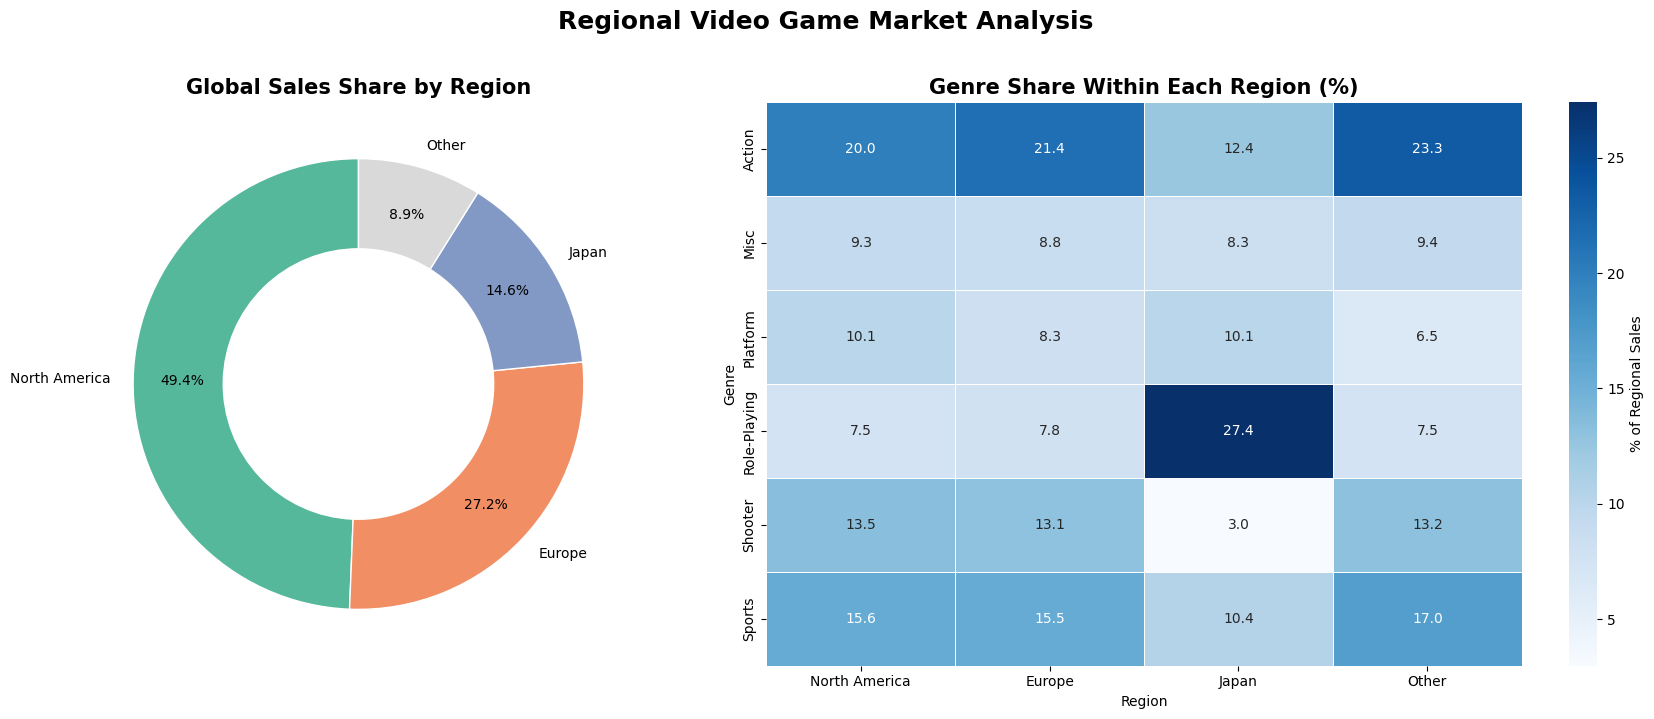

In [59]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 7),
    gridspec_kw={'width_ratios': [1, 1.35]}
)

region_colors = [
    '#55B89A',
    '#F28E63',
    '#8299C5',
    '#D9D9D9'
]

axes[0].pie(
    regional_sales.values,
    labels=regional_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.78,
    colors=region_colors,
    wedgeprops={
        'width': 0.40,
        'edgecolor': 'white'
    }
)

axes[0].set_title(
    'Global Sales Share by Region',
    fontsize=15,
    fontweight='bold'
)

sns.heatmap(
    region_genre_share,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5,
    cbar_kws={
        'label': '% of Regional Sales'
    },
    ax=axes[1]
)

axes[1].set_title(
    'Genre Share Within Each Region (%)',
    fontsize=15,
    fontweight='bold'
)

axes[1].set_xlabel('Region')
axes[1].set_ylabel('Genre')

axes[1].set_xticklabels(
    [
        'North America',
        'Europe',
        'Japan',
        'Other'
    ],
    rotation=0
)


fig.suptitle(
    'Regional Video Game Market Analysis',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

## Regional Mix of Top 10 Platforms


In [60]:
top10_platforms = (
    df_clean
    .groupby('Platform')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

platform_region_sales = (
    df_clean[
        df_clean['Platform'].isin(top10_platforms)
    ]
    .groupby('Platform')[
        [
            'NA_Sales',
            'EU_Sales',
            'JP_Sales',
            'Other_Sales'
        ]
    ]
    .sum()
)

platform_region_sales
platform_region_share = (
    platform_region_sales
    .div(
        platform_region_sales.sum(axis=1),
        axis=0
    )
    * 100
)

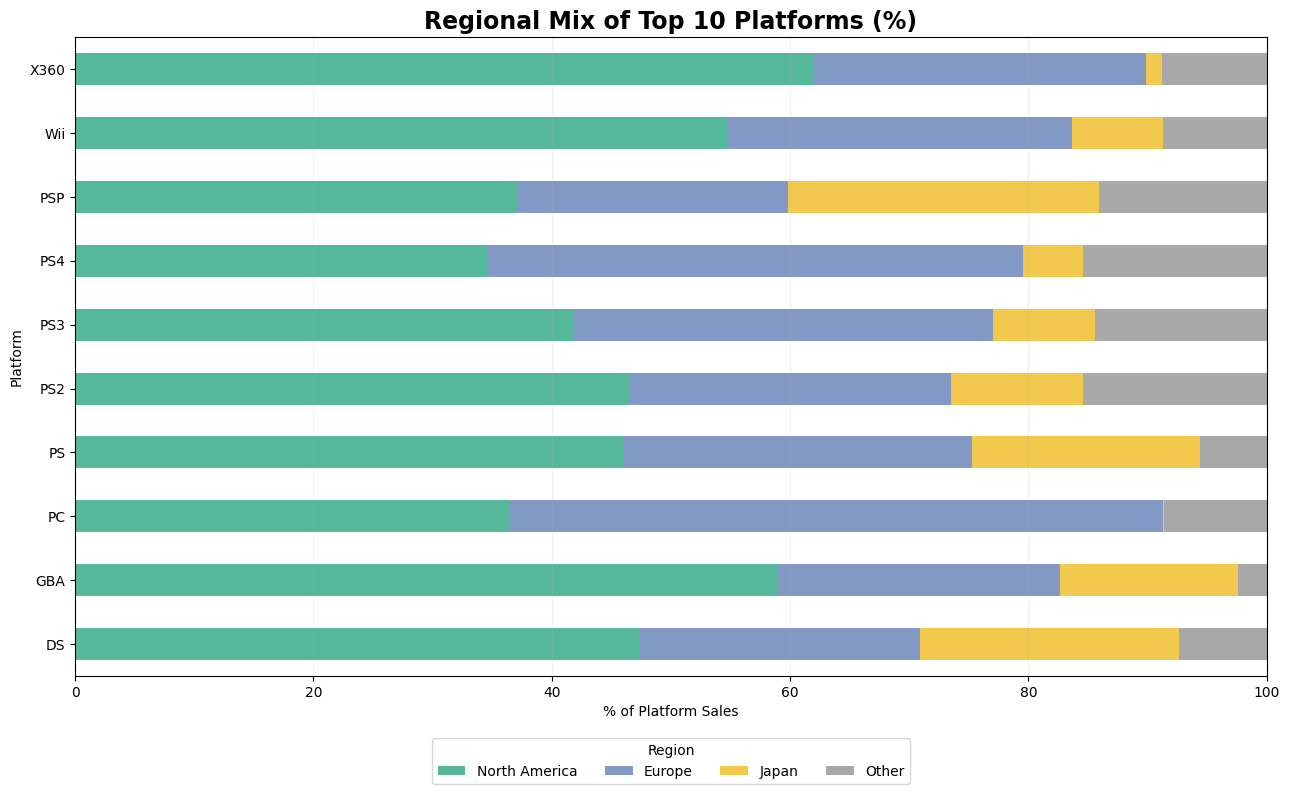

In [61]:
region_colors = {
    'NA_Sales': '#55B89A',
    'EU_Sales': '#8299C5',
    'JP_Sales': '#F2C94C',
    'Other_Sales': '#A8A8A8'
}

ax = platform_region_share.plot(
    kind='barh',
    stacked=True,
    figsize=(13, 8),
    color=[
        region_colors['NA_Sales'],
        region_colors['EU_Sales'],
        region_colors['JP_Sales'],
        region_colors['Other_Sales']
    ]
)

plt.title(
    'Regional Mix of Top 10 Platforms (%)',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel(
    '% of Platform Sales'
)

plt.ylabel(
    'Platform'
)

plt.xlim(0, 100)

plt.legend(
    title='Region',
    labels=[
        'North America',
        'Europe',
        'Japan',
        'Other'
    ],
    loc='lower center',
    bbox_to_anchor=(0.5, -0.18),
    ncol=4
)

plt.grid(
    axis='x',
    alpha=0.2
)

plt.tight_layout()
plt.show()

# Rating vs Sales Analysis

In [62]:
critic_data = df_clean[
    ['Critic_Score', 'Global_Sales']
].dropna()

print("Games with Critic Score:", len(critic_data))

critic_corr = critic_data[
    'Critic_Score'
].corr(
    critic_data['Global_Sales']
)

print(
    f"Critic Score vs Global Sales Correlation: "
    f"{critic_corr:.3f}"
)

Games with Critic Score: 8137
Critic Score vs Global Sales Correlation: 0.245


In [63]:
user_data = df_clean[
    ['User_Score', 'Global_Sales']
].dropna()

print("Games with User Score:", len(user_data))
user_corr = user_data[
    'User_Score'
].corr(
    user_data['Global_Sales']
)

print(
    f"User Score vs Global Sales Correlation: "
    f"{user_corr:.3f}"
)

Games with User Score: 7590
User Score vs Global Sales Correlation: 0.088


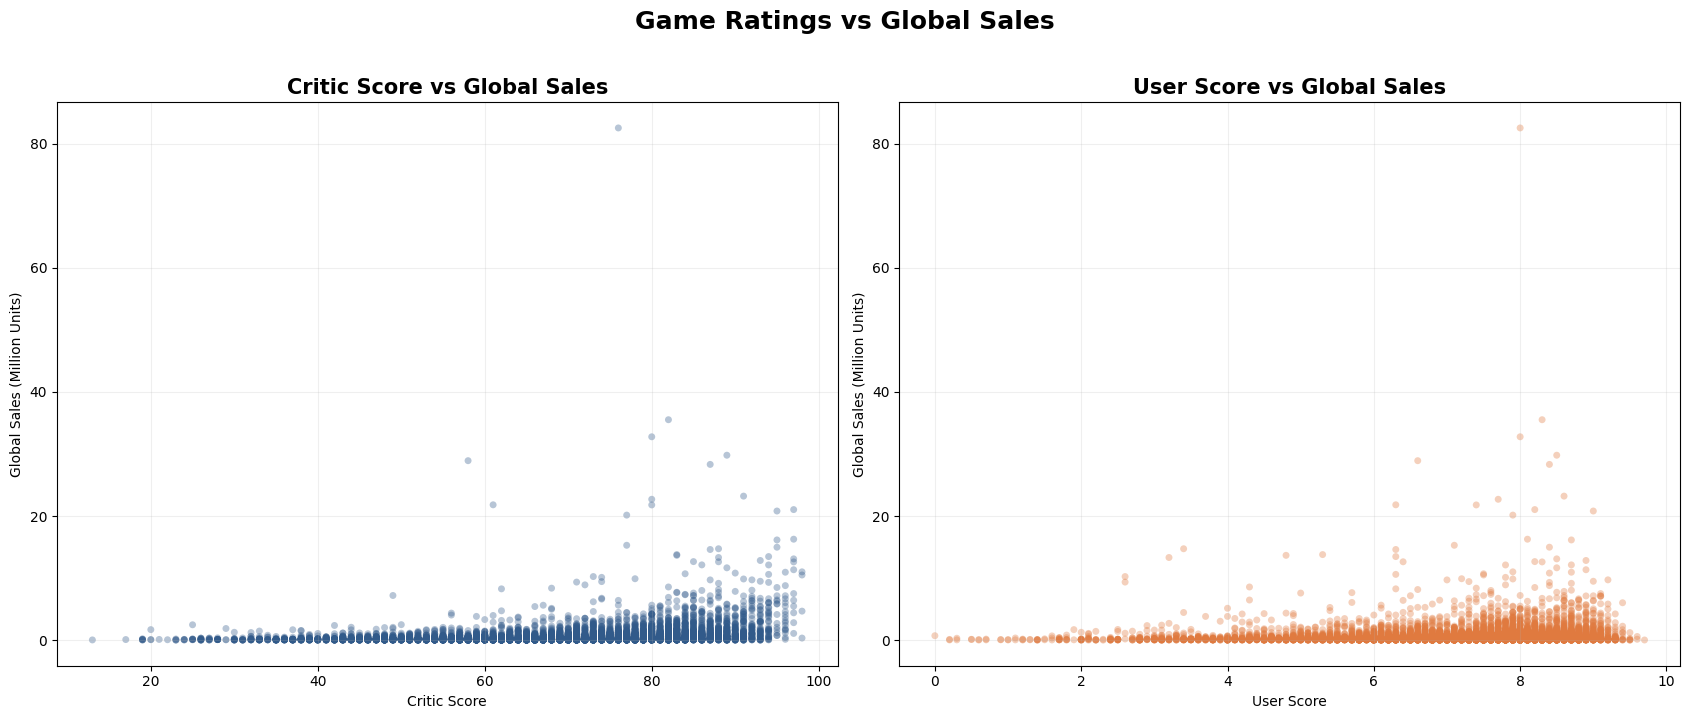

In [64]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7)
)

axes[0].scatter(
    critic_data['Critic_Score'],
    critic_data['Global_Sales'],
    alpha=0.35,
    s=25,
    color='#315A8A',
    edgecolors='none'
)

axes[0].set_title(
    'Critic Score vs Global Sales',
    fontsize=15,
    fontweight='bold'
)

axes[0].set_xlabel('Critic Score')
axes[0].set_ylabel('Global Sales (Million Units)')

axes[0].grid(alpha=0.2)

axes[1].scatter(
    user_data['User_Score'],
    user_data['Global_Sales'],
    alpha=0.35,
    s=25,
    color='#E07A3F',
    edgecolors='none'
)

axes[1].set_title(
    'User Score vs Global Sales',
    fontsize=15,
    fontweight='bold'
)

axes[1].set_xlabel('User Score')
axes[1].set_ylabel('Global Sales (Million Units)')

axes[1].grid(alpha=0.2)

fig.suptitle(
    'Game Ratings vs Global Sales',
    fontsize=18,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()

In [65]:
df_clean.to_csv("Video_Games_Cleaned.csv", index=False)

from google.colab import files
files.download("Video_Games_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 💡 Final Business Insights

### 1. Genre Performance
Action is the most common genre in the dataset, with **3,369 games**, and also generates the highest total global sales at **1,745.26 million units**. However, Platform games have the highest average sales per game at **0.933 million units**, showing that market size and sales efficiency are not always the same.

### 2. Platform Performance
PS2 is the highest-selling platform, generating **1,255.64 million units** in global sales, and it also has the largest game library with **2,161 games**. This indicates strong historical performance supported by a large portfolio.

### 3. Publisher Dominance
Nintendo is the leading publisher with **1,788.81 million units** in global sales. It also has the highest average sales per game among publishers with at least 30 games, reaching approximately **2.53 million units per game**.

### 4. Market Concentration
The **top 15 publishers account for 80.37%** of total recorded global sales. This indicates a highly concentrated publisher market where a relatively small number of major companies generate a large share of industry sales.

### 5. Best-Selling Games
**Wii Sports** is the best-selling game in the dataset, with **82.53 million units** sold globally. Interestingly, the top 10 best-selling games together represent only **4.13%** of total global sales, indicating that sales are not dependent on only a small number of individual blockbuster games.

### 6. Market Trend
The video game market reached its highest annual global sales in **2008**, with **671.79 million units**. By **2015**, annual sales had decreased to **268.05 million units**, representing a **60.10% decline** from the 2008 peak. The 2016 data should be interpreted cautiously because it represents a partial year.

### 7. Regional Market
**North America** is the largest regional market, contributing **49.37%** of total recorded sales, followed by **Europe at 27.20%** and **Japan at 14.56%**. This highlights the importance of North America and Europe when evaluating market opportunities.

### 8. Ratings and Sales
Critic scores have a stronger positive relationship with global sales (**correlation = 0.245**) than user scores (**correlation = 0.088**). Although the relationship is not strong enough to imply causation, higher critic scores are associated with higher average sales.

### 9. Impact of Critical Reception
Games with an **Excellent Critic Score (85–100)** achieved an average of **1.973 million units** in global sales, compared with only **0.229 million units** for games with Low Critic Scores (0–49). This suggests that product quality and critical reception can be important indicators of commercial performance.

### 10. Overall Finding
The analysis indicates that video game success is influenced by multiple factors, including **genre, platform, publisher strength, regional demand, market timing, and product quality**. Therefore, companies should evaluate these factors together rather than relying on a single metric when planning new game releases.

# 🎯 Business Recommendations

### 1. Focus on Market Demand and Sales Efficiency
Companies should evaluate both the popularity of a genre and its average sales per game before investing in a new title. A genre with many releases is not necessarily the most efficient in terms of sales per game.

### 2. Prioritize Key Regional Markets
North America and Europe should receive strong consideration in marketing, distribution, and launch strategies because they represent the largest shares of recorded global sales.

### 3. Learn from Leading Publishers
The strong performance of major publishers, particularly Nintendo, suggests that companies can benefit from studying successful publisher strategies, including platform selection, franchise development, genre positioning, and portfolio management.

### 4. Invest in Game Quality
The positive relationship between critic scores and sales, combined with the substantially higher average sales of highly rated games, supports investing in game quality, testing, design, and overall player experience.

### 5. Consider Platform Strategy Carefully
Historical platform performance shows that platform selection can have a major impact on commercial success. Companies should consider platform audience, lifecycle, regional popularity, and historical sales performance when deciding where to launch a game.

### 6. Use Regional and Genre Preferences
Regional differences in genre and platform performance can be used to create more targeted marketing campaigns and product strategies rather than applying the same approach to every market.

### 7. Monitor Market Cycles
The decline in annual sales after the 2008 peak highlights the importance of monitoring market trends and platform lifecycles before making long-term investment and release decisions.